### Phase 1: Multi-Asset Financial Data Ingestion & Causal GARCH(1,1) Engine
Builds the leakage-safe panel (`NIFTY50`, `SPY`, `USDINR`, `EURUSD`) with:
 - Log-transformed Garman-Klass realized volatility target
 - Causal rolling volatility & return features
 - Out-of-sample GARCH(1,1) conditional volatility features
 - Strict chronological train/val/cal/test splits & regime tags

In [12]:
import os
import warnings
import numpy as np
import pandas as pd
import yfinance as yf
from arch import arch_model

warnings.filterwarnings("ignore")

os.makedirs("data", exist_ok=True)
os.makedirs("artifacts", exist_ok=True)

ASSETS = {
    "NIFTY50": {"ticker": "^NSEI",    "asset_class": "Equity"},
    "SPY":     {"ticker": "SPY",      "asset_class": "Equity"},
    "USDINR":  {"ticker": "INR=X",    "asset_class": "FX"},
    "EURUSD":  {"ticker": "EURUSD=X", "asset_class": "FX"},
}

START_DATE = "2007-01-01"
END_DATE   = "2026-11-01"

# Strict Chronological Splits (Zero Future Leakage)
TRAIN_END = "2020-12-31"   # Fit scalers, GARCH parameters, and neural weights
VAL_END   = "2022-12-31"   # Hyperparameter tuning & early stopping
CAL_END   = "2024-10-31"   # Unseen hold-out set for Conformal Calibration
# 2024-11-01 to 2026-11-01 -> Untouched Final Test Set

EPS = 1e-8
VOL_WINDOW = 21  # ~1 trading month rolling realized volatility window
print("Configuration initialized successfully.")

Configuration initialized successfully.


#### Cell 2: Realized Volatility & Causal GARCH(1,1) Functions

In [13]:
def compute_garman_klass_vol(df: pd.DataFrame, window: int = 21) -> pd.Series:
    """
    Computes annualized Garman-Klass range-based realized volatility using OHLC.
    Falls back to squared close-to-close log returns if OHLC range is zero/missing.
    """
    log_hl = np.log(df["High"] / df["Low"].replace(0, np.nan))
    log_co = np.log(df["Close"] / df["Open"].replace(0, np.nan))
    gk_daily = 0.5 * (log_hl ** 2) - (2.0 * np.log(2.0) - 1.0) * (log_co ** 2)

    log_ret = np.log(df["Close"] / df["Close"].shift(1))
    daily_var = gk_daily.where(gk_daily > 0, log_ret ** 2)

    rv = np.sqrt(daily_var.rolling(window=window, min_periods=window).mean() * 252.0)
    return rv


def fit_causal_garch(returns: pd.Series, train_end: str) -> tuple[pd.Series, dict]:
    """
    Fits GARCH(1,1) with Student-t innovations strictly up to `train_end`
    (or first 70% if ticker history starts late), then filters 1-step-ahead
    conditional variance forward without look-ahead bias.
    """
    scaled_ret = returns * 100.0
    train_subset = scaled_ret.loc[scaled_ret.index <= pd.Timestamp(train_end)]

    if len(train_subset) < 100:
        # Fallback if Yahoo Finance history for a ticker starts later than expected
        cutoff_pos = int(len(scaled_ret) * 0.70)
        last_train_idx = scaled_ret.index[cutoff_pos]
        print(f"  [Warning] Short history detected (starts {scaled_ret.index[0].date()}). "
              f"Using 70% cutoff ({last_train_idx.date()}) for GARCH fit.")
    else:
        last_train_idx = train_subset.index[-1]

    am = arch_model(scaled_ret, vol="Garch", p=1, q=1, mean="Constant", dist="t")
    res = am.fit(last_obs=last_train_idx, disp="off")

    forecasts = res.forecast(horizon=1, start=scaled_ret.index[0], reindex=False)
    cond_var = forecasts.variance["h.1"]
    garch_vol = np.sqrt(cond_var / (100.0 ** 2) * 252.0)

    params_summary = {
        "omega": float(res.params.get("omega", np.nan)),
        "alpha[1]": float(res.params.get("alpha[1]", np.nan)),
        "beta[1]": float(res.params.get("beta[1]", np.nan)),
        "nu (df)": float(res.params.get("nu", np.nan)),
        "persistence (alpha+beta)": float(
            res.params.get("alpha[1]", 0.0) + res.params.get("beta[1]", 0.0)
        ),
    }
    return garch_vol, params_summary

#### Cell 3: Download, Engineer Features, Fit GARCH & Construct Panel

In [14]:
all_frames = []
garch_diagnostics = {}

for asset_id, meta in ASSETS.items():
    print(f"Processing {asset_id} ({meta['ticker']})...")
    raw = yf.download(meta["ticker"], start=START_DATE, end=END_DATE, progress=False)

    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)
    raw.index = pd.to_datetime(raw.index).tz_localize(None)
    print(f"  Downloaded {len(raw)} rows ({raw.index.min().date()} to {raw.index.max().date()})")

    df = raw[["Open", "High", "Low", "Close", "Volume"]].copy()
    df = df.dropna(subset=["Close"])
    df = df[df["Close"] > 0]

    # 1. Target: Log Realized Volatility
    df["log_return"] = np.log(df["Close"] / df["Close"].shift(1))
    df["rv_21d"] = compute_garman_klass_vol(df, window=VOL_WINDOW)
    df["target_log_rv"] = np.log(df["rv_21d"] + EPS)

    # 2. Causal Rolling Volatility & Shock Features (known at time t)
    df["rv_5d"] = df["log_return"].rolling(5).std() * np.sqrt(252.0)
    df["rv_63d"] = df["log_return"].rolling(63).std() * np.sqrt(252.0)
    df["abs_return"] = df["log_return"].abs()
    df["sq_return"] = df["log_return"] ** 2
    df["vol_ratio_5_21"] = df["rv_5d"] / (df["rv_21d"] + EPS)

    df = df.dropna(subset=["log_return", "target_log_rv", "rv_63d"]).copy()

    # 3. Causal GARCH(1,1) Conditional Volatility
    df["garch_vol"], garch_params = fit_causal_garch(df["log_return"], TRAIN_END)
    df["log_garch_vol"] = np.log(df["garch_vol"] + EPS)
    garch_diagnostics[asset_id] = garch_params

    # 4. Future-Known Calendar Covariates (TFT schema)
    df["day_of_week"] = df.index.dayofweek.astype(str)
    df["month"] = df.index.month.astype(str)
    df["day_of_month"] = df.index.day
    df["is_turn_of_month"] = ((df.index.day <= 3) | (df.index.day >= 28)).astype(int)

    # 5. Static Metadata & Contiguous Time Index
    df["asset_id"] = asset_id
    df["asset_class"] = meta["asset_class"]
    df = df.reset_index().rename(columns={"Date": "date"})
    df["date"] = pd.to_datetime(df["date"]).dt.tz_localize(None)
    df["time_idx"] = np.arange(len(df))

    # 6. Chronological Split Assignment
    df["split"] = np.where(
        df["date"] <= TRAIN_END, "train",
        np.where(
            df["date"] <= VAL_END, "val",
            np.where(df["date"] <= CAL_END, "cal", "test")
        )
    )

    # 7. Leakage-Free Volatility Regime Labels (based strictly on train percentiles)
    train_rv = df.loc[df["split"] == "train", "rv_21d"]
    q33, q67 = train_rv.quantile([0.33, 0.67])
    df["vol_regime"] = np.select(
        [df["rv_21d"] <= q33, df["rv_21d"] <= q67],
        ["low", "medium"],
        default="high"
    )

    all_frames.append(df)

panel_df = pd.concat(all_frames, ignore_index=True)
panel_df.to_parquet("data/financial_vol_panel.parquet", index=False)
panel_df.to_csv("data/financial_vol_panel.csv", index=False)
print("\nSaved panel to data/financial_vol_panel.parquet and .csv")

Processing NIFTY50 (^NSEI)...
  Downloaded 4691 rows (2007-09-17 to 2026-10-30)
Processing SPY (SPY)...
  Downloaded 4989 rows (2007-01-03 to 2026-10-30)
Processing USDINR (INR=X)...
  Downloaded 5141 rows (2007-01-01 to 2026-10-30)
Processing EURUSD (EURUSD=X)...
  Downloaded 5143 rows (2007-01-01 to 2026-10-30)

Saved panel to data/financial_vol_panel.parquet and .csv


#### Cell 4: Phase 1 Verification & Diagnostics

In [15]:
print("=== Fitted GARCH(1,1) Parameters (Training Split Only) ===")
garch_summary_df = pd.DataFrame(garch_diagnostics).T
print(garch_summary_df.round(4))

print("\n=== Row Counts per Asset & Chronological Split ===")
print(pd.crosstab(panel_df["asset_id"], panel_df["split"], margins=True))

print("\n=== Volatility Regime Distribution across Splits ===")
print(pd.crosstab(panel_df["split"], panel_df["vol_regime"], normalize="index").round(3))

# Quick sanity check: verify zero NaNs in model columns
assert panel_df.drop(columns=["Volume"]).isna().sum().sum() == 0, "Unexpected NaNs detected!"
print("\nSanity check passed: 0 NaNs across all feature and target columns.")

=== Fitted GARCH(1,1) Parameters (Training Split Only) ===
          omega  alpha[1]  beta[1]  nu (df)  persistence (alpha+beta)
NIFTY50  0.0168    0.0804   0.9093   7.3738                    0.9898
SPY      0.0191    0.1604   0.8396   5.1426                    1.0000
USDINR   0.0041    0.0908   0.8965   6.0594                    0.9873
EURUSD   0.0026    0.0433   0.9498   5.5167                    0.9932

=== Row Counts per Asset & Chronological Split ===
split      cal  test  train   val    All
asset_id                                
EURUSD     479   516   3564   521   5080
NIFTY50    451   493   3188   496   4628
SPY        461   500   3462   503   4926
USDINR     479   516   3562   521   5078
All       1870  2025  13776  2041  19712

=== Volatility Regime Distribution across Splits ===
vol_regime   high    low  medium
split                           
cal         0.065  0.635   0.300
test        0.129  0.498   0.373
train       0.330  0.330   0.340
val         0.308  0.402   0.290


### Phase 2: Training Baselines (M1, M2) & Neural Models (M3 DeepAR, M4 TFT, M5 GARCH-TFT)
 Outputs 9-decile predictions (0.1 to 0.9) for horizons h=1..5 on `cal` and `test` splits.

In [16]:
import os
import warnings
import numpy as np
import pandas as pd
from scipy.stats import norm

import torch
import lightning.pytorch as pl
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint

from pytorch_forecasting import TimeSeriesDataSet, TemporalFusionTransformer, DeepAR
from pytorch_forecasting.data import GroupNormalizer
from pytorch_forecasting.data.encoders import NaNLabelEncoder
from pytorch_forecasting.metrics import QuantileLoss, NormalDistributionLoss

warnings.filterwarnings("ignore")
pl.seed_everything(42, workers=True)

device_str = (
    f"CUDA ({torch.cuda.get_device_name(0)})"
    if torch.cuda.is_available()
    else "CPU"
)
print(f"Running Phase 2 on: {device_str}")

Seed set to 42


Running Phase 2 on: CUDA (NVIDIA GeForce RTX 3050 Laptop GPU)


In [17]:
class CleanEpochPrinter(pl.Callback):
    def __init__(self):
        self.best_val = float("inf")

    def on_validation_epoch_end(self, trainer, pl_module):
        if trainer.sanity_checking:
            return
        epoch = trainer.current_epoch + 1
        t_loss = trainer.callback_metrics.get("train_loss_epoch", float("nan"))
        v_loss = trainer.callback_metrics.get("val_loss", float("nan"))
        improved = ""
        if v_loss < self.best_val:
            self.best_val = float(v_loss)
            improved = "  <-- NEW BEST (saved)"
        print(f"Epoch {epoch:02d} | train_loss: {t_loss:.4f} | val_loss: {v_loss:.4f}{improved}")

#### Cell 2: Load Panel & Define Forecasting Configuration

In [18]:
panel_df = pd.read_parquet("data/financial_vol_panel.parquet")
for categorical_column in ["asset_id", "asset_class", "day_of_week", "month"]:
    panel_df[categorical_column] = panel_df[categorical_column].astype(str)

DECILES = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
MAX_ENCODER_LENGTH = 60   # 60 trading days (~3 months) lookback
MAX_PREDICTION_LENGTH = 5 # 5 trading days (1-week) multi-horizon forecast
BATCH_SIZE = 128 if torch.cuda.is_available() else 64
MAX_EPOCHS = 30

# Helper to build leakage-free rolling windows for val / cal / test splits
def create_eval_dataset(base_train_ds: TimeSeriesDataSet, full_df: pd.DataFrame, target_split: str) -> TimeSeriesDataSet:
    """
    Constructs rolling evaluation windows where every predicted target step lies strictly
    inside `target_split`, while encoder context looks back `MAX_ENCODER_LENGTH` days.
    """
    split_order = ["train", "val", "cal", "test"]
    max_idx_allowed = split_order.index(target_split)
    allowed_splits = split_order[: max_idx_allowed + 1]

    sub_df = full_df[full_df["split"].isin(allowed_splits)].copy()

    # Minimum prediction index per asset so predictions start strictly inside `target_split`
    min_pred_idx = int(full_df.loc[full_df["split"] == target_split, "time_idx"].min())

    return TimeSeriesDataSet.from_dataset(
        base_train_ds,
        sub_df,
        predict=False,
        min_prediction_idx=min_pred_idx,
        stop_randomization=True,
    )

#### Cell 3: Helper to Extract & Align Predictions with Ground Truth Metadata

In [19]:
def extract_predictions_df(
    raw_quantiles: np.ndarray,
    index_df: pd.DataFrame,
    full_df: pd.DataFrame,
    model_name: str,
) -> pd.DataFrame:
    """
    Maps model quantile array of shape (N_windows, H, 9) onto a tidy DataFrame with
    `asset_id`, `origin_time_idx`, `target_time_idx`, `horizon`, `y_true`, `garch_vol`,
    `vol_regime`, `split`, and columns `q_0.1` .. `q_0.9`.
    """
    records = []
    n_windows, H, _ = raw_quantiles.shape

    # Lookup dictionary for fast ground-truth & metadata alignment
    lookup = full_df.set_index(["asset_id", "time_idx"])[
        ["date", "target_log_rv", "rv_21d", "garch_vol", "log_garch_vol", "vol_regime", "split"]
    ]

    for i in range(n_windows):
        asset = index_df.iloc[i]["asset_id"]
        first_pred_t = int(index_df.iloc[i]["time_idx"])
        origin_t = first_pred_t - 1
        origin_garch = float(lookup.loc[(asset, origin_t), "garch_vol"])
        origin_regime = str(lookup.loc[(asset, origin_t), "vol_regime"])

        for h in range(H):
            t_target = first_pred_t + h
            if (asset, t_target) not in lookup.index:
                continue
            row_meta = lookup.loc[(asset, t_target)]
            rec = {
                "model": model_name,
                "asset_id": asset,
                "origin_time_idx": origin_t,
                "target_time_idx": t_target,
                "target_date": row_meta["date"],
                "horizon": h + 1,
                "split": row_meta["split"],
                "origin_garch_vol": origin_garch,
                "origin_regime": origin_regime,
                "target_regime": row_meta["vol_regime"],
                "y_true": float(row_meta["target_log_rv"]),
            }
            for q_idx, q_val in enumerate(DECILES):
                rec[f"q_{q_val:.1f}"] = float(raw_quantiles[i, h, q_idx])
            records.append(rec)

    return pd.DataFrame(records)

#### Cell 4: Build TimeSeriesDataSets for TFT (Standard vs GARCH) & DeepAR

In [20]:
train_df = panel_df[panel_df["split"] == "train"].copy()

COMMON_STATIC_CATS = ["asset_id", "asset_class"]
COMMON_KNOWN_CATS = ["day_of_week", "month"]
COMMON_KNOWN_REALS = ["time_idx", "day_of_month", "is_turn_of_month"]

BASE_UNKNOWN_REALS = [
    "target_log_rv",
    "log_return",
    "rv_5d",
    "rv_63d",
    "abs_return",
    "vol_ratio_5_21",
]
GARCH_UNKNOWN_REALS = BASE_UNKNOWN_REALS + ["garch_vol", "log_garch_vol"]

# 1. Standard TFT Dataset (M4)
tft_base_train_ds = TimeSeriesDataSet(
    train_df,
    time_idx="time_idx",
    target="target_log_rv",
    group_ids=["asset_id"],
    min_encoder_length=MAX_ENCODER_LENGTH,
    max_encoder_length=MAX_ENCODER_LENGTH,
    min_prediction_length=MAX_PREDICTION_LENGTH,
    max_prediction_length=MAX_PREDICTION_LENGTH,
    static_categoricals=COMMON_STATIC_CATS,
    time_varying_known_categoricals=COMMON_KNOWN_CATS,
    time_varying_known_reals=COMMON_KNOWN_REALS,
    time_varying_unknown_reals=BASE_UNKNOWN_REALS,
    target_normalizer=GroupNormalizer(groups=["asset_id"], transformation=None),
    categorical_encoders={"day_of_week": NaNLabelEncoder(add_nan=True)},
    add_relative_time_idx=True,
    add_target_scales=True,
    add_encoder_length=True,
)

# 2. GARCH-TFT Dataset (M5)
tft_garch_train_ds = TimeSeriesDataSet(
    train_df,
    time_idx="time_idx",
    target="target_log_rv",
    group_ids=["asset_id"],
    min_encoder_length=MAX_ENCODER_LENGTH,
    max_encoder_length=MAX_ENCODER_LENGTH,
    min_prediction_length=MAX_PREDICTION_LENGTH,
    max_prediction_length=MAX_PREDICTION_LENGTH,
    static_categoricals=COMMON_STATIC_CATS,
    time_varying_known_categoricals=COMMON_KNOWN_CATS,
    time_varying_known_reals=COMMON_KNOWN_REALS,
    time_varying_unknown_reals=GARCH_UNKNOWN_REALS,
    target_normalizer=GroupNormalizer(groups=["asset_id"], transformation=None),
    categorical_encoders={"day_of_week": NaNLabelEncoder(add_nan=True)},
    add_relative_time_idx=True,
    add_target_scales=True,
    add_encoder_length=True,
)

# 3. DeepAR Dataset (M3 - autoregressive target only in unknown_reals)
deepar_train_ds = TimeSeriesDataSet(
    train_df,
    time_idx="time_idx",
    target="target_log_rv",
    group_ids=["asset_id"],
    min_encoder_length=MAX_ENCODER_LENGTH,
    max_encoder_length=MAX_ENCODER_LENGTH,
    min_prediction_length=MAX_PREDICTION_LENGTH,
    max_prediction_length=MAX_PREDICTION_LENGTH,
    static_categoricals=COMMON_STATIC_CATS,
    time_varying_known_categoricals=COMMON_KNOWN_CATS,
    time_varying_known_reals=COMMON_KNOWN_REALS,
    time_varying_unknown_reals=["target_log_rv"],
    target_normalizer=GroupNormalizer(groups=["asset_id"], transformation=None),
    categorical_encoders={"day_of_week": NaNLabelEncoder(add_nan=True)},
)

print("TimeSeriesDataSets constructed successfully.")

TimeSeriesDataSets constructed successfully.


#### Cell 5: Train & Evaluate M3 (DeepAR via NLL + Monte Carlo Deciles)

In [21]:
print("\n=== Training M3: DeepAR ===")
deepar_train_loader = deepar_train_ds.to_dataloader(train=True, batch_size=BATCH_SIZE, num_workers=0)
deepar_val_ds = create_eval_dataset(deepar_train_ds, panel_df, "val")
deepar_val_loader = deepar_val_ds.to_dataloader(train=False, batch_size=BATCH_SIZE * 2, num_workers=0)

deepar_ckpt = ModelCheckpoint(dirpath="artifacts/deepar", monitor="val_loss", mode="min", save_top_k=1, save_last=True)
deepar_trainer = pl.Trainer(
    max_epochs=MAX_EPOCHS,
    accelerator="auto",
    devices=1,
    gradient_clip_val=0.1,
    callbacks=[EarlyStopping(monitor="val_loss", patience=5, mode="min"), deepar_ckpt, CleanEpochPrinter()],
    enable_progress_bar=True,
)

deepar_resume_path = os.path.join("artifacts/deepar", "last.ckpt")
if os.path.exists(deepar_resume_path):
    print(f"Starting a new DeepAR session from weights in {deepar_resume_path}")
    deepar_model = DeepAR.load_from_checkpoint(deepar_resume_path)
else:
    deepar_model = DeepAR.from_dataset(
        deepar_train_ds,
        learning_rate=1e-3,
        hidden_size=64,
        rnn_layers=2,
        dropout=0.1,
        loss=NormalDistributionLoss(),
    )
deepar_trainer.fit(
    deepar_model,
    train_dataloaders=deepar_train_loader,
    val_dataloaders=deepar_val_loader,
)
best_deepar = DeepAR.load_from_checkpoint(deepar_ckpt.best_model_path)

deepar_preds_list = []
for split_name in ["cal", "test"]:
    eval_ds = create_eval_dataset(deepar_train_ds, panel_df, split_name)
    eval_loader = eval_ds.to_dataloader(train=False, batch_size=BATCH_SIZE * 2, num_workers=0)
    raw_out = best_deepar.predict(eval_loader, mode="raw", n_samples=200, return_index=True)
    # raw_out.output.prediction shape: (N, H, n_samples)
    samples = raw_out.output.prediction.detach().cpu()
    q_tensor = torch.quantile(samples, torch.tensor(DECILES), dim=-1).permute(1, 2, 0).numpy()
    deepar_preds_list.append(extract_predictions_df(q_tensor, raw_out.index, panel_df, "M3_DeepAR"))

deepar_preds_df = pd.concat(deepar_preds_list, ignore_index=True)
deepar_preds_df.to_parquet("artifacts/preds_M3_DeepAR.parquet", index=False)
print("Saved M3_DeepAR predictions:", deepar_preds_df.shape)


=== Training M3: DeepAR ===


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name                   | Type                   | Params | Mode  | FLOPs
----------------------------------------------------------------------------------
0 | loss                   | NormalDistributionLoss | 0      | train | 0    
1 | logging_metrics        | ModuleList             | 0      | train | 0    
2 | embeddings             | MultiEmbedding         | 110    | train | 0    
3 | rnn                    | LSTM                   | 54.8 K | train | 0    
4 | distribution_projector | Linear                 | 130    | train | 0    
----------------------------------------------------------------------------------
55.0 K    Trainable

Epoch 11: 100%|██████████| 105/105 [00:25<00:00,  4.12it/s, v_num=12, train_loss_step=-1.57, val_loss=-1.88, train_loss_epoch=-1.70]


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelC

Saved M3_DeepAR predictions: (30455, 20)


#### Cell 6: Train & Evaluate M4 (Standard TFT) and M5 (GARCH-TFT)

In [22]:
def run_tft_experiment(train_ds: TimeSeriesDataSet, model_name: str, ckpt_dir: str) -> pd.DataFrame:
    print(f"\n=== Training {model_name} ===")
    train_loader = train_ds.to_dataloader(train=True, batch_size=BATCH_SIZE, num_workers=0)
    val_ds = create_eval_dataset(train_ds, panel_df, "val")
    val_loader = val_ds.to_dataloader(train=False, batch_size=BATCH_SIZE * 2, num_workers=0)

    ckpt_cb = ModelCheckpoint(dirpath=ckpt_dir, monitor="val_loss", mode="min", save_top_k=1, save_last=True)
    trainer = pl.Trainer(
        max_epochs=MAX_EPOCHS,
        accelerator="auto",
        devices=1,
        gradient_clip_val=0.1,
        callbacks=[EarlyStopping(monitor="val_loss", patience=5, mode="min"), ckpt_cb, CleanEpochPrinter()],
        enable_progress_bar=True,
    )

    tft_resume_path = os.path.join(ckpt_dir, "last.ckpt")
    if os.path.exists(tft_resume_path):
        print(f"Starting a new {model_name} session from weights in {tft_resume_path}")
        tft = TemporalFusionTransformer.load_from_checkpoint(tft_resume_path)
    else:
        tft = TemporalFusionTransformer.from_dataset(
            train_ds,
            learning_rate=1e-3,
            hidden_size=64,
            attention_head_size=4,
            dropout=0.15,
            hidden_continuous_size=32,
            output_size=len(DECILES),
            loss=QuantileLoss(quantiles=DECILES),
            reduce_on_plateau_patience=3,
        )
    trainer.fit(tft, train_dataloaders=train_loader, val_dataloaders=val_loader)
    best_tft = TemporalFusionTransformer.load_from_checkpoint(ckpt_cb.best_model_path)

    out_frames = []
    for split_name in ["cal", "test"]:
        eval_ds = create_eval_dataset(train_ds, panel_df, split_name)
        eval_loader = eval_ds.to_dataloader(train=False, batch_size=BATCH_SIZE * 2, num_workers=0)
        pred_out = best_tft.predict(eval_loader, mode="quantiles", return_index=True)
        q_arr = pred_out.output.detach().cpu().numpy()  # (N, H, 9)
        out_frames.append(extract_predictions_df(q_arr, pred_out.index, panel_df, model_name))

    df_out = pd.concat(out_frames, ignore_index=True)
    df_out.to_parquet(f"artifacts/preds_{model_name}.parquet", index=False)
    print(f"Saved {model_name} predictions:", df_out.shape)
    return df_out

tft_base_preds_df = run_tft_experiment(tft_base_train_ds, "M4_TFT_Base", "artifacts/tft_base")
tft_garch_preds_df = run_tft_experiment(tft_garch_train_ds, "M5_TFT_GARCH", "artifacts/tft_garch")


=== Training M4_TFT_Base ===


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

   | Name                               | Type                            | Params | Mode  | FLOPs
--------------------------------------------------------------------------------------------------------
0  | loss                               | QuantileLoss                    | 0      | train | 0    
1  | logging_metrics                    | ModuleList                      | 0      | train | 0    
2  | input_embeddings                   | MultiEmbedding                  | 110    | train | 0    
3  | prescalers                         | ModuleDict                      | 832    | train | 0    
4  | static_variable_selection          | Varia

Epoch 18: 100%|██████████| 105/105 [00:40<00:00,  2.58it/s, v_num=15, train_loss_step=0.0385, val_loss=0.0382, train_loss_epoch=0.044]


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelC

Saved M4_TFT_Base predictions: (30455, 20)

=== Training M5_TFT_GARCH ===


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

   | Name                               | Type                            | Params | Mode  | FLOPs
--------------------------------------------------------------------------------------------------------
0  | loss                               | QuantileLoss                    | 0      | train | 0    
1  | logging_metrics                    | ModuleList                      | 0      | train | 0    
2  | input_embeddings                   | MultiEmbedding                  | 110    | train | 0    
3  | prescalers                         | ModuleDict                      | 960    | train | 0    
4  | static_variable_selection          | VariableSelectionNetwork        | 21.2 K | train | 0    
5  | encoder_variable_selection         | VariableSelectionNetwork        | 88.2 K | train | 0    
6  | decoder_variable_selection         | VariableSelectionNetwork        | 28.6 K | train | 0    
7  | static_context_variable_selection  | GatedResidualNetwo

Epoch 29: 100%|██████████| 105/105 [00:54<00:00,  1.91it/s, v_num=18, train_loss_step=0.0358, val_loss=0.0358, train_loss_epoch=0.0394]

`Trainer.fit` stopped: `max_epochs=30` reached.


Epoch 29: 100%|██████████| 105/105 [00:55<00:00,  1.89it/s, v_num=18, train_loss_step=0.0358, val_loss=0.0358, train_loss_epoch=0.0394]


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelC

Saved M5_TFT_GARCH predictions: (30455, 20)


#### Cell 7: Generate Classical Baselines M1 (Persistence) & M2 (GARCH(1,1)) on Same Windows
 - Use M5's exact evaluation index grid so every model is scored on identical forecast origins

In [23]:
template_df = tft_garch_preds_df[
    ["asset_id", "origin_time_idx", "target_time_idx", "target_date", "horizon",
     "split", "origin_garch_vol", "origin_regime", "target_regime", "y_true"]
].copy()

lookup_origin = panel_df.set_index(["asset_id", "time_idx"])[["target_log_rv", "log_garch_vol"]]

# Estimate empirical residual std on training set for parametric intervals
train_panel = panel_df[panel_df["split"] == "train"]
persist_err_std = (train_panel["target_log_rv"] - train_panel.groupby("asset_id")["target_log_rv"].shift(1)).std()
garch_err_std = (train_panel["target_log_rv"] - train_panel["log_garch_vol"]).std()

z_scores = norm.ppf(DECILES)

m1_rows, m2_rows = [], []
for _, row in template_df.iterrows():
    key = (row["asset_id"], int(row["origin_time_idx"]))
    h = int(row["horizon"])
    last_y = float(lookup_origin.loc[key, "target_log_rv"])
    last_garch = float(lookup_origin.loc[key, "log_garch_vol"])

    r1 = row.to_dict()
    r1["model"] = "M1_Persistence"
    r2 = row.to_dict()
    r2["model"] = "M2_GARCH"

    for q_val, z in zip(DECILES, z_scores):
        # Uncertainty scales with sqrt(horizon)
        r1[f"q_{q_val:.1f}"] = last_y + z * persist_err_std * np.sqrt(h)
        r2[f"q_{q_val:.1f}"] = last_garch + z * garch_err_std * np.sqrt(h)

    m1_rows.append(r1)
    m2_rows.append(r2)

m1_df = pd.DataFrame(m1_rows)
m2_df = pd.DataFrame(m2_rows)
m1_df.to_parquet("artifacts/preds_M1_Persistence.parquet", index=False)
m2_df.to_parquet("artifacts/preds_M2_GARCH.parquet", index=False)

print("All Phase 2 models (M1–M5) trained and predictions saved to artifacts/!")

All Phase 2 models (M1–M5) trained and predictions saved to artifacts/!


Cell 8: Phase 3 & 4 Setup (Reusing existing os, np, pd, DECILES)

In [24]:
# %% Cell 8: Phase 3 & 4 Setup (Reusing existing os, np, pd, DECILES)
import glob
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("artifacts/figures", exist_ok=True)
sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)

model_files = {
    "M1_Persistence": "artifacts/preds_M1_Persistence.parquet",
    "M2_GARCH":       "artifacts/preds_M2_GARCH.parquet",
    "M3_DeepAR":      "artifacts/preds_M3_DeepAR.parquet",
    "M4_TFT_Base":    "artifacts/preds_M4_TFT_Base.parquet",
    "M5_TFT_GARCH":   "artifacts/preds_M5_TFT_GARCH.parquet",
}

preds_panel = pd.concat(
    [pd.read_parquet(path) for path in model_files.values() if os.path.exists(path)],
    ignore_index=True,
)
print(f"Loaded Phase 2 predictions: {preds_panel.shape[0]:,} rows across {preds_panel['model'].nunique()} models.")

Loaded Phase 2 predictions: 152,275 rows across 5 models.


Phase 3 — Volatility-Aware Conformal Calibration (M6_VA_C_TFT)

In [25]:
# %% Cell 9: Build Volatility-Aware Conformal Calibrator (M6_VA_C_TFT)
ALPHA = 0.20  # Target 80% central prediction interval [q_0.1, q_0.9]
LOWER_Q, UPPER_Q = "q_0.1", "q_0.9"

# 1. Extract unseen chronological calibration split from M5_TFT_GARCH
m5_full = preds_panel[preds_panel["model"] == "M5_TFT_GARCH"].copy()
cal_df = m5_full[m5_full["split"] == "cal"].copy()

# 2. Compute GARCH-normalized non-conformity scores: s_t = max(L_t - y_t, y_t - U_t, 0) / v_t
raw_error = np.maximum(
    cal_df[LOWER_Q] - cal_df["y_true"],
    np.maximum(cal_df["y_true"] - cal_df[UPPER_Q], 0.0),
)
norm_scores = raw_error / (cal_df["origin_garch_vol"] + 1e-8)

# 3. Compute (1 - alpha) empirical quantile threshold Q_{1 - alpha}
q_hat = float(np.quantile(norm_scores, 1.0 - ALPHA))
print(f"Volatility-Aware Conformal Threshold (Q_{1 - ALPHA:.2f}): {q_hat:.4f}")

# 4. Dynamically expand/contract M5 intervals using causal GARCH volatility v_t
m6_df = m5_full.copy()
m6_df["model"] = "M6_VA_C_TFT"
expansion = q_hat * m6_df["origin_garch_vol"]

m6_df[LOWER_Q] = m6_df[LOWER_Q] - expansion
m6_df[UPPER_Q] = m6_df[UPPER_Q] + expansion

m6_df.to_parquet("artifacts/preds_M6_VA_C_TFT.parquet", index=False)
preds_panel = pd.concat([preds_panel, m6_df], ignore_index=True)
print("Saved M6_VA_C_TFT and appended to master evaluation panel.")

Volatility-Aware Conformal Threshold (Q_0.80): 0.8264
Saved M6_VA_C_TFT and appended to master evaluation panel.


Phase 4A — Master Evaluation Table (Gneiting et al., 2007 Metrics)

In [26]:
# %% Cell 10: Compute Pinball Loss, Coverage, Sharpness, Interval Score & CRPS
def pinball_loss(y_true: np.ndarray, y_pred: np.ndarray, tau: float) -> np.ndarray:
    err = y_true - y_pred
    return np.maximum(tau * err, (tau - 1.0) * err)

def interval_score(y_true: np.ndarray, lower: np.ndarray, upper: np.ndarray, alpha: float = 0.20) -> np.ndarray:
    width = upper - lower
    under_pen = (2.0 / alpha) * np.maximum(lower - y_true, 0.0)
    over_pen = (2.0 / alpha) * np.maximum(y_true - upper, 0.0)
    return width + under_pen + over_pen

eval_rows = []
for (model_name, split_name), grp in preds_panel.groupby(["model", "split"]):
    y = grp["y_true"].values
    lo, hi = grp["q_0.1"].values, grp["q_0.9"].values

    mean_pb = np.mean([np.mean(pinball_loss(y, grp[f"q_{q:.1f}"].values, q)) for q in DECILES])
    coverage_80 = np.mean((y >= lo) & (y <= hi))
    sharpness_80 = np.mean(hi - lo)
    mean_is = np.mean(interval_score(y, lo, hi, alpha=ALPHA))

    eval_rows.append({
        "Model": model_name,
        "Split": split_name,
        "Pinball Loss (CRPS)": round(mean_pb, 4),
        "80% Coverage": round(coverage_80, 4),
        "Interval Width (Sharpness)": round(sharpness_80, 4),
        "Interval Score": round(mean_is, 4),
    })

metrics_df = pd.DataFrame(eval_rows)
print("=== Master Performance Table (Test Split) ===")
print(metrics_df[metrics_df["Split"] == "test"].sort_values("Interval Score").to_string(index=False))

=== Master Performance Table (Test Split) ===
         Model Split  Pinball Loss (CRPS)  80% Coverage  Interval Width (Sharpness)  Interval Score
     M3_DeepAR  test               0.0327        0.7630                      0.1877          0.4388
M1_Persistence  test               0.0304        0.9049                      0.2641          0.4528
   M4_TFT_Base  test               0.0312        0.7784                      0.1646          0.4620
  M5_TFT_GARCH  test               0.0359        0.6559                      0.1633          0.5327
   M6_VA_C_TFT  test               0.0365        0.8909                      0.3377          0.5850
      M2_GARCH  test               0.1237        0.8979                      1.2620          1.6611


Phase 4B — Volatility Regime & Horizon Breakdown

In [27]:
# %% Cell 11: Stratified Evaluation Across Volatility Regimes & Horizons (Test Split)
test_panel = preds_panel[preds_panel["split"] == "test"].copy()
test_panel["covered_80"] = (test_panel["y_true"] >= test_panel["q_0.1"]) & (test_panel["y_true"] <= test_panel["q_0.9"])
test_panel["width_80"] = test_panel["q_0.9"] - test_panel["q_0.1"]

print("=== 80% Coverage by Volatility Regime (Test Split) ===")
regime_cov = test_panel.pivot_table(index="model", columns="target_regime", values="covered_80", aggfunc="mean")
print(regime_cov[["low", "medium", "high"]].round(4))

print("\n=== Mean Interval Width (Sharpness) by Volatility Regime (Test Split) ===")
regime_wid = test_panel.pivot_table(index="model", columns="target_regime", values="width_80", aggfunc="mean")
print(regime_wid[["low", "medium", "high"]].round(4))

print("\n=== 80% Coverage Across Forecast Horizons h=1..5 (Test Split) ===")
horizon_cov = test_panel.pivot_table(index="model", columns="horizon", values="covered_80", aggfunc="mean")
print(horizon_cov.round(4))

=== 80% Coverage by Volatility Regime (Test Split) ===
target_regime      low  medium    high
model                                 
M1_Persistence  0.9241  0.9191  0.7908
M2_GARCH        0.9249  0.9493  0.6473
M3_DeepAR       0.7372  0.8302  0.6695
M4_TFT_Base     0.7794  0.8334  0.6168
M5_TFT_GARCH    0.6368  0.7120  0.5687
M6_VA_C_TFT     0.8717  0.9640  0.7557

=== Mean Interval Width (Sharpness) by Volatility Regime (Test Split) ===
target_regime      low  medium    high
model                                 
M1_Persistence  0.2641  0.2640  0.2639
M2_GARCH        1.2624  1.2618  1.2614
M3_DeepAR       0.1668  0.1788  0.2928
M4_TFT_Base     0.1653  0.1579  0.1813
M5_TFT_GARCH    0.1666  0.1415  0.2133
M6_VA_C_TFT     0.3035  0.3473  0.4411

=== 80% Coverage Across Forecast Horizons h=1..5 (Test Split) ===
horizon              1       2       3       4       5
model                                                 
M1_Persistence  0.9438  0.9200  0.9027  0.8855  0.8728
M2_GARCH      

Phase 4C — Sharpness Diagram & PIT Histograms

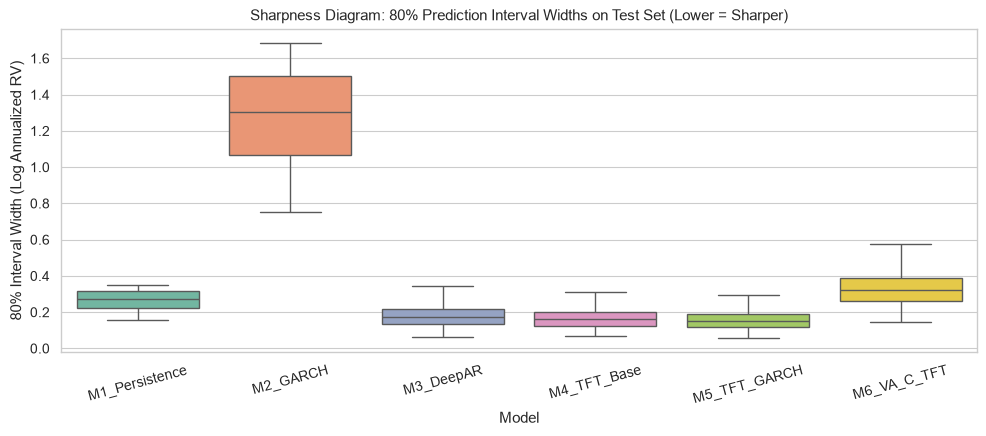

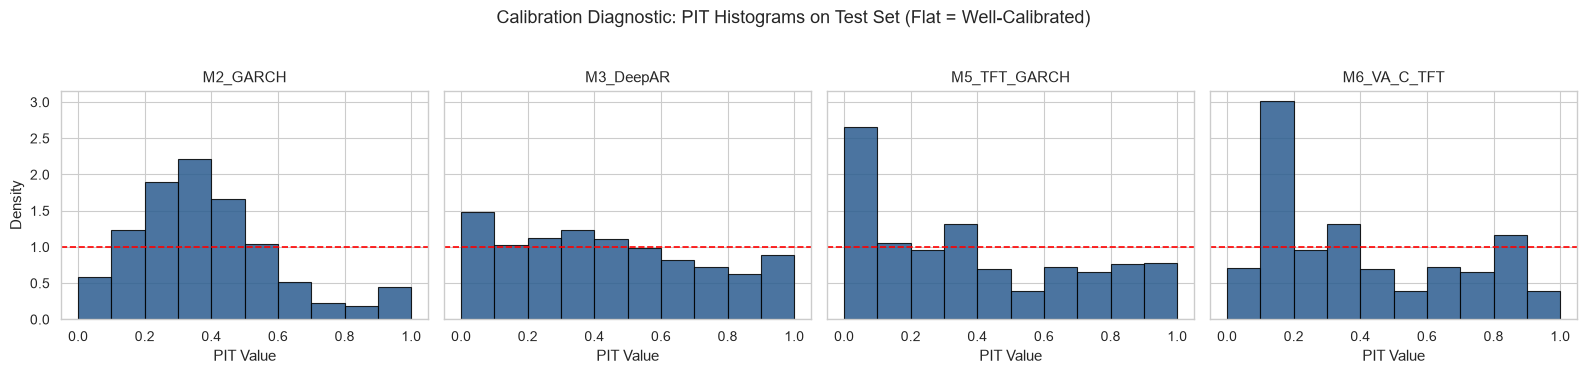

In [28]:
# %% Cell 12: Plot Sharpness Diagram (Boxplots) & PIT Calibration Histograms
q_cols = [f"q_{q:.1f}" for q in DECILES]
model_order = [m for m in ["M1_Persistence", "M2_GARCH", "M3_DeepAR", "M4_TFT_Base", "M5_TFT_GARCH", "M6_VA_C_TFT"] if m in test_panel["model"].unique()]

# 1. Sharpness Diagram (Gneiting et al. Fig. 9)
plt.figure(figsize=(10, 4.5))
sns.boxplot(data=test_panel, x="model", y="width_80", order=model_order, showfliers=False, palette="Set2")
plt.title("Sharpness Diagram: 80% Prediction Interval Widths on Test Set (Lower = Sharper)")
plt.xlabel("Model")
plt.ylabel("80% Interval Width (Log Annualized RV)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("artifacts/figures/fig1_sharpness_diagram.png", dpi=300)
plt.show()

# 2. Empirical PIT Histograms (Gneiting et al. Fig. 1)
def compute_empirical_pit(df_sub: pd.DataFrame) -> np.ndarray:
    y = df_sub["y_true"].values
    q_mat = df_sub[q_cols].values
    grid_p = np.array([0.0] + DECILES + [1.0])
    pits = np.zeros(len(y))
    for i in range(len(y)):
        spread = max(q_mat[i, -1] - q_mat[i, 0], 1e-6)
        grid_q = np.concatenate([[q_mat[i, 0] - 0.25 * spread], q_mat[i], [q_mat[i, -1] + 0.25 * spread]])
        pits[i] = np.interp(y[i], grid_q, grid_p)
    return pits

pit_models = [m for m in ["M2_GARCH", "M3_DeepAR", "M5_TFT_GARCH", "M6_VA_C_TFT"] if m in test_panel["model"].unique()]
fig, axes = plt.subplots(1, len(pit_models), figsize=(4 * len(pit_models), 3.6), sharey=True)

for ax, m_name in zip(axes, pit_models):
    pit_vals = compute_empirical_pit(test_panel[test_panel["model"] == m_name])
    ax.hist(pit_vals, bins=10, range=(0, 1), density=True, color="#2b5c8f", edgecolor="black", alpha=0.85)
    ax.axhline(1.0, color="red", linestyle="--", linewidth=1.2)
    ax.set_title(m_name)
    ax.set_xlabel("PIT Value")

axes[0].set_ylabel("Density")
plt.suptitle("Calibration Diagnostic: PIT Histograms on Test Set (Flat = Well-Calibrated)", y=1.03)
plt.tight_layout()
plt.savefig("artifacts/figures/fig2_pit_histograms.png", dpi=300)
plt.show()

Phase 4D — Calibrated Fan Chart & TFT Variable Importance

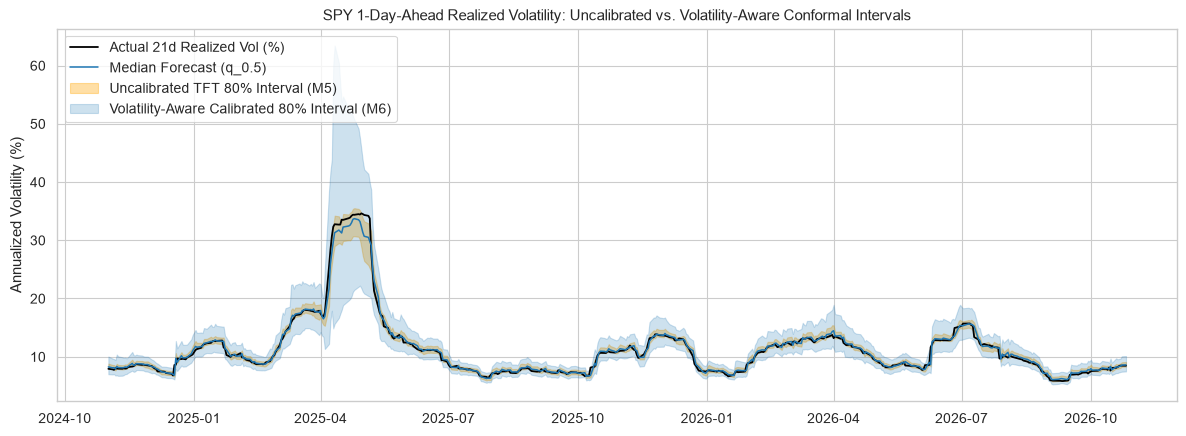

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


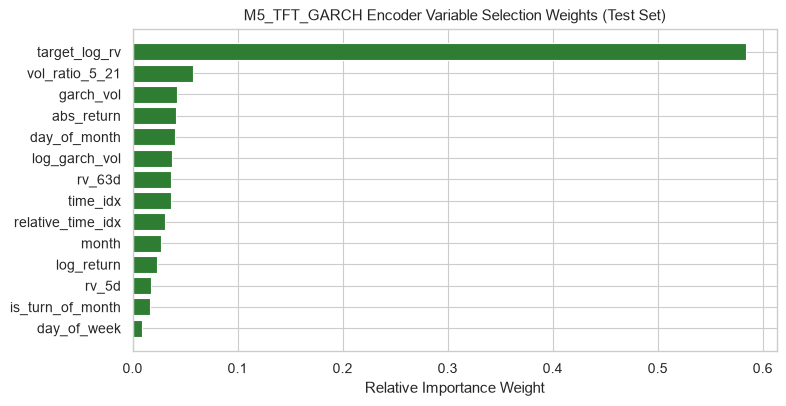

In [29]:
# %% Cell 13: Plot SPY Fan Chart (M5 vs M6) & M5_TFT_GARCH Variable Selection Weights
# 1. SPY 1-Day-Ahead Fan Chart
spy_m5 = test_panel[(test_panel["asset_id"] == "SPY") & (test_panel["horizon"] == 1) & (test_panel["model"] == "M5_TFT_GARCH")].sort_values("target_date")
spy_m6 = test_panel[(test_panel["asset_id"] == "SPY") & (test_panel["horizon"] == 1) & (test_panel["model"] == "M6_VA_C_TFT")].sort_values("target_date")

plt.figure(figsize=(12, 4.5))
plt.plot(spy_m6["target_date"], np.exp(spy_m6["y_true"]) * 100, color="black", linewidth=1.3, label="Actual 21d Realized Vol (%)")
plt.plot(spy_m6["target_date"], np.exp(spy_m6["q_0.5"]) * 100, color="#1f77b4", linewidth=1.1, label="Median Forecast (q_0.5)")
plt.fill_between(spy_m5["target_date"], np.exp(spy_m5["q_0.1"]) * 100, np.exp(spy_m5["q_0.9"]) * 100, color="orange", alpha=0.35, label="Uncalibrated TFT 80% Interval (M5)")
plt.fill_between(spy_m6["target_date"], np.exp(spy_m6["q_0.1"]) * 100, np.exp(spy_m6["q_0.9"]) * 100, color="#1f77b4", alpha=0.22, label="Volatility-Aware Calibrated 80% Interval (M6)")
plt.title("SPY 1-Day-Ahead Realized Volatility: Uncalibrated vs. Volatility-Aware Conformal Intervals")
plt.ylabel("Annualized Volatility (%)")
plt.legend(loc="upper left")
plt.tight_layout()
plt.savefig("artifacts/figures/fig3_spy_calibrated_fan_chart.png", dpi=300)
plt.show()

# 2. Extract Encoder Variable Importance from M5_TFT_GARCH
garch_ckpts = [p for p in glob.glob("artifacts/tft_garch/*.ckpt") if "last" not in p]
if garch_ckpts:
    best_tft_garch = TemporalFusionTransformer.load_from_checkpoint(max(garch_ckpts, key=os.path.getmtime))
    test_ds = create_eval_dataset(tft_garch_train_ds, panel_df, "test")
    test_loader = test_ds.to_dataloader(train=False, batch_size=256, num_workers=0)

    raw_preds = best_tft_garch.predict(test_loader, mode="raw", return_x=True)
    interp = best_tft_garch.interpret_output(raw_preds.output, reduction="sum")

    enc_imp = interp["encoder_variables"].detach().cpu().numpy()
    imp_df = pd.DataFrame({
        "Feature": best_tft_garch.encoder_variables,
        "Importance": enc_imp / enc_imp.sum(),
    }).sort_values("Importance", ascending=True)

    plt.figure(figsize=(8, 4.2))
    plt.barh(imp_df["Feature"], imp_df["Importance"], color="#2e7d32")
    plt.title("M5_TFT_GARCH Encoder Variable Selection Weights (Test Set)")
    plt.xlabel("Relative Importance Weight")
    plt.tight_layout()
    plt.savefig("artifacts/figures/fig4_tft_variable_importance.png", dpi=300)
    plt.show()